# Edgewise Causal Fidelity and OOD Readiness

This CPU analysis consolidates the completed representation, binding, composition, terminal-use, and query-conditional experiments into an auditable edgewise causal-fidelity profile.

[实验设置与运行说明](../../../docs/experiment_notes/12_cross_study_audits_and_pilots/44e1285655f73836.md)


In [1]:
# Run once. Every later code cell reports cell-level progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 14 tracked cells.')

Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 14 tracked cells.


## 1. Inputs and frozen evidence protocol


In [2]:
%%cell_progress 1/14 Locate VisualTorque and import analysis dependencies
cell_stage('Locating the project')
from pathlib import Path
import hashlib
import json
import os
import sys
from datetime import datetime, timezone
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

def find_project_root():
    configured = os.environ.get('VISUALTORQUE_ROOT')
    candidates = []
    if configured:
        candidates.append(Path(configured).expanduser())
    if IN_COLAB:
        candidates.extend((
            Path('/content/drive/MyDrive/VisualTorque'),
            Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
        ))
    for base in (Path.cwd(), *Path.cwd().parents):
        candidates.extend((base, base / 'VisualTorque'))
    checked = set()
    for candidate in candidates:
        try:
            candidate = candidate.resolve()
        except OSError:
            continue
        if candidate in checked:
            continue
        checked.add(candidate)
        if (candidate / 'results').is_dir() and (
            (candidate / 'toolkit').is_dir()
            or (candidate / 'notebooks').is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        'Could not locate VisualTorque. Mount Drive, start Jupyter inside the '
        'repository, or set VISUALTORQUE_ROOT.'
    )

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

PROJECT_ROOT = find_project_root()
RESULTS_ROOT = PROJECT_ROOT / 'results'
OUTPUT_DIR = RESULTS_ROOT / 'edgewise_causal_fidelity_ood_readiness_v1'
FIGURE_DIR = OUTPUT_DIR / 'figures'
for path in (OUTPUT_DIR, FIGURE_DIR):
    path.mkdir(parents=True, exist_ok=True)
print('Project:', PROJECT_ROOT)
print('Output:', OUTPUT_DIR)

Locate VisualTorque and import analysis dependencies:   0%|          | 0/14 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque
Output: /content/drive/MyDrive/VisualTorque/results/edgewise_causal_fidelity_ood_readiness_v1


In [3]:
%%cell_progress 2/14 Prepare Dataset v1 metadata
cell_stage('Resolving Dataset v1')

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}

def dataset_complete(root):
    return root.is_dir() and all((root / name).is_file() for name in REQUIRED_DATASET_FILES)

dataset_candidates = []
if IN_COLAB:
    dataset_candidates.append(Path('/content/visualtorque_dataset_v1'))
dataset_candidates.extend((
    PROJECT_ROOT / 'data' / 'dataset_v1',
    PROJECT_ROOT.parent / 'data' / 'dataset_v1',
))
DATASET_DIR = next((path for path in dataset_candidates if dataset_complete(path)), None)

if DATASET_DIR is None:
    archives = (
        PROJECT_ROOT / 'data' / 'dataset_v1.zip',
        PROJECT_ROOT.parent / 'data' / 'dataset_v1.zip',
    )
    archive = next((path for path in archives if path.is_file()), None)
    if archive is None:
        raise FileNotFoundError(
            'Dataset v1 was not found as a directory or dataset_v1.zip.'
        )
    DATASET_DIR = (
        Path('/content/visualtorque_dataset_v1')
        if IN_COLAB else OUTPUT_DIR / '_dataset_cache'
    )
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    cell_stage('Extracting Dataset v1 metadata')
    with ZipFile(archive, 'r') as bundle:
        members = [member for member in bundle.infolist() if not member.is_dir()]
        root_resolved = DATASET_DIR.resolve()
        for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
            target = (DATASET_DIR / member.filename).resolve()
            if target != root_resolved and root_resolved not in target.parents:
                raise ValueError(f'Unsafe archive path: {member.filename}')
            bundle.extract(member, DATASET_DIR)
    nested = [path for path in DATASET_DIR.rglob('scenes.jsonl')]
    if not dataset_complete(DATASET_DIR) and len(nested) == 1:
        DATASET_DIR = nested[0].parent

assert dataset_complete(DATASET_DIR), DATASET_DIR
scenes = read_jsonl(DATASET_DIR / 'scenes.jsonl')
split_manifest = read_json(DATASET_DIR / 'splits.json')
assert len(scenes) == 2100, len(scenes)
print('Dataset:', DATASET_DIR)
print('Scenes:', len(scenes))

Prepare Dataset v1 metadata:   7%|7         | 1/14 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1
Scenes: 2100


In [4]:
%%cell_progress 3/14 Resolve and hash completed mechanism artifacts
cell_stage('Resolving frozen source artifacts')

def resolve_artifact(exact_relative, filename, required_tokens=()):
    exact = RESULTS_ROOT / exact_relative
    if exact.is_file():
        return exact
    candidates = []
    for path in RESULTS_ROOT.rglob(filename):
        lowered = str(path).lower()
        if all(token.lower() in lowered for token in required_tokens):
            candidates.append(path)
    if len(candidates) == 1:
        return candidates[0]
    raise FileNotFoundError(
        f'Could not uniquely locate {filename}. Expected {exact}; '
        f'candidates={candidates}'
    )

ARTIFACT_PATHS = {
    'representation': resolve_artifact(
        Path('representation_specificity_v1') / 'specificity_summary.json',
        'specificity_summary.json', ('representation_specificity_v1',),
    ),
    'orthogonal_claim': resolve_artifact(
        Path('orthogonal_value_binding_control_v1') / 'robustness_audit_v1' / 'claim_card.json',
        'claim_card.json', ('orthogonal_value_binding_control_v1', 'robustness_audit_v1'),
    ),
    'qwen9_orthogonal': resolve_artifact(
        Path('orthogonal_value_binding_control_v1') / 'models' / 'Qwen__Qwen3.5-9B'
        / 'analysis' / 'orthogonal_value_binding_decision.json',
        'orthogonal_value_binding_decision.json', ('qwen3.5-9b',),
    ),
    'gemma12_orthogonal': resolve_artifact(
        Path('orthogonal_value_binding_control_v1') / 'models' / 'google__gemma-4-12B-it'
        / 'analysis' / 'orthogonal_value_binding_decision.json',
        'orthogonal_value_binding_decision.json', ('gemma-4-12b-it',),
    ),
    'qwen27_large': resolve_artifact(
        Path('large_model_frozen_claim_replication_v1') / 'models'
        / 'Qwen__Qwen3.5-27B__373612cb' / 'analysis'
        / 'large_model_frozen_claim_decision.json',
        'large_model_frozen_claim_decision.json', ('large_model_frozen_claim_replication_v1',),
    ),
    'qwen27_depth': resolve_artifact(
        Path('qwen27b_depth_relocalization_audit_v1') / 'models'
        / 'Qwen__Qwen3.5-27B__373612cb' / 'analysis'
        / 'depth_relocalization_decision.json',
        'depth_relocalization_decision.json', ('qwen27b_depth_relocalization_audit_v1',),
    ),
    'qwen27_terminal': resolve_artifact(
        Path('qwen27b_torque_to_answer_bridge_v1') / 'models'
        / 'Qwen__Qwen3.5-27B__373612cb' / 'analysis'
        / 'terminal_bridge_decision.json',
        'terminal_bridge_decision.json', ('qwen27b_torque_to_answer_bridge_v1',),
    ),
    'qwen27_query': resolve_artifact(
        Path('qwen27b_query_conditional_torque_use_v1') / 'models'
        / 'Qwen__Qwen3.5-27B__373612cb' / 'analysis'
        / 'query_conditional_decision.json',
        'query_conditional_decision.json', ('qwen27b_query_conditional_torque_use_v1',),
    ),
}

artifacts = {name: read_json(path) for name, path in ARTIFACT_PATHS.items()}
artifact_hashes = {name: sha256_file(path) for name, path in ARTIFACT_PATHS.items()}
artifact_table = pd.DataFrame([
    {'artifact': name, 'path': str(path), 'sha256': artifact_hashes[name]}
    for name, path in ARTIFACT_PATHS.items()
])
artifact_table.to_csv(OUTPUT_DIR / 'source_artifacts.csv', index=False)
display(artifact_table[['artifact', 'path']])

Resolve and hash completed mechanism artifacts:  14%|#4        | 2/14 [00:00<?, ?cell/s]

,artifact,path
0,representation,/content/drive/MyDrive/VisualTorque/results/re...
1,orthogonal_claim,/content/drive/MyDrive/VisualTorque/results/or...
2,qwen9_orthogonal,/content/drive/MyDrive/VisualTorque/results/or...
3,gemma12_orthogonal,/content/drive/MyDrive/VisualTorque/results/or...
4,qwen27_large,/content/drive/MyDrive/VisualTorque/results/la...
5,qwen27_depth,/content/drive/MyDrive/VisualTorque/results/qw...
6,qwen27_terminal,/content/drive/MyDrive/VisualTorque/results/qw...
7,qwen27_query,/content/drive/MyDrive/VisualTorque/results/qw...


In [5]:
%%cell_progress 4/14 Freeze edge definitions and inference limits
cell_stage('Locking the edgewise synthesis protocol')

EDGE_ORDER = (
    'representation', 'binding', 'factor_to_torque',
    'side_to_net', 'torque_to_answer', 'query_selection',
)
EDGE_LABELS = {
    'representation': 'Physical variables represented',
    'binding': 'Factors bound to the correct object/side',
    'factor_to_torque': 'Weight and distance composed into side torque',
    'side_to_net': 'Left/right torques aggregated into net torque',
    'torque_to_answer': 'Torque state causally controls the answer',
    'query_selection': 'Torque route selectively recruited by the query',
}
STATUS_ORDER = ('supported', 'partial', 'not_supported', 'inconclusive', 'not_tested')
MIN_FORMAL_MODEL_STATES = 8
MIN_MODEL_FAMILIES = 3
SEED = 20261018

protocol_identity = {
    'schema_version': 'visualtorque-edgewise-fidelity-readiness-1.0',
    'source_hashes': artifact_hashes,
    'dataset_splits_sha256': sha256_file(DATASET_DIR / 'splits.json'),
    'edges': list(EDGE_ORDER),
    'status_vocabulary': list(STATUS_ORDER),
    'status_rule': (
        'supported requires the source experiment predefined gate; partial '
        'requires positive upstream evidence but failure of a stronger lawful '
        'composition/use gate; not_supported is local to the frozen intervention; '
        'inconclusive is underpowered or conflicting; not_tested has no direct test'
    ),
    'aggregation_rule': 'No scalar causal-fidelity score is estimated in this notebook.',
    'stress_partition_limit': (
        'Dataset v1 probe_test is a benchmark composition/structure holdout, '
        'not the unknown pretraining OOD distribution of a zero-shot VLM.'
    ),
    'formal_prediction_gate': {
        'minimum_complete_model_states': MIN_FORMAL_MODEL_STATES,
        'minimum_model_families': MIN_MODEL_FAMILIES,
        'requires_frozen_scalar_or_prespecified_multivariate_model': True,
        'requires_ID_accuracy_confidence_and_probe_covariates': True,
        'requires_leave_one_family_out_validation': True,
    },
    'seed': SEED,
}
PROTOCOL_PATH = OUTPUT_DIR / 'protocol_lock.json'
if PROTOCOL_PATH.is_file():
    previous = read_json(PROTOCOL_PATH)
    assert previous.get('identity') == protocol_identity, (
        'Inputs or rules changed. Use a new versioned output directory.'
    )
else:
    write_json_atomic(PROTOCOL_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })
print('Protocol:', PROTOCOL_PATH)

Freeze edge definitions and inference limits:  21%|##1       | 3/14 [00:00<?, ?cell/s]

Protocol: /content/drive/MyDrive/VisualTorque/results/edgewise_causal_fidelity_ood_readiness_v1/protocol_lock.json


## 2. Edgewise mechanism synthesis


In [6]:
%%cell_progress 5/14 Parse representation evidence
cell_stage('Extracting representation-specificity decisions')

representation_rows = []
representation_summary = artifacts['representation']
for raw_name, payload in representation_summary.get('models', {}).items():
    lowered = str(raw_name).lower()
    if 'qwen' in lowered:
        model_key = 'qwen9b'
    elif 'gemma' in lowered:
        model_key = 'gemma12b'
    else:
        continue
    decision = payload.get('specificity_decision', {})
    specificity = str(decision.get('specificity_status', ''))
    if specificity == 'strong_specificity_support':
        status = 'supported'
    elif specificity == 'partial_specificity_support':
        status = 'partial'
    elif specificity == 'specificity_not_supported':
        status = 'not_supported'
    else:
        status = 'inconclusive'
    representation_rows.append({
        'model': model_key,
        'edge': 'representation',
        'status': status,
        'source_artifact': 'representation',
        'source_decision': specificity or 'missing_specificity_status',
        'evidence': (
            'Activation information tested after additive primitive controls '
            'and exact additive-feature matching.'
        ),
    })

assert {row['model'] for row in representation_rows} == {'qwen9b', 'gemma12b'}
display(pd.DataFrame(representation_rows))

Parse representation evidence:  29%|##8       | 4/14 [00:00<?, ?cell/s]

,model,edge,status,source_artifact,source_decision,evidence
0,qwen9b,representation,supported,representation,strong_specificity_support,Activation information tested after additive p...
1,gemma12b,representation,supported,representation,strong_specificity_support,Activation information tested after additive p...


In [7]:
%%cell_progress 6/14 Parse binding and factor-to-torque evidence
cell_stage('Extracting orthogonal-control decisions')

edge_rows = list(representation_rows)
orthogonal_claims = artifacts['orthogonal_claim'].get('claims', {})
assert orthogonal_claims.get(
    'shared_factor_specific_binding_under_scalar_orthogonality'
) is True

for model, artifact_name in (
    ('qwen9b', 'qwen9_orthogonal'),
    ('gemma12b', 'gemma12_orthogonal'),
):
    decision = artifacts[artifact_name]
    binding_supported = bool(decision.get('factor_binding_supported', False))
    torque_equivalent = bool(
        decision.get('side_torque_equivalence_supported', False)
    )
    weight_dominant = bool(decision.get('weight_dominant_side_torque', False))
    late_use = bool(decision.get('late_outcome_use_supported', False))
    edge_rows.append({
        'model': model, 'edge': 'binding',
        'status': 'supported' if binding_supported else 'not_supported',
        'source_artifact': artifact_name,
        'source_decision': str(decision.get('decision')),
        'evidence': 'Scalar-orthogonal factor-specific causal patching.',
    })
    if torque_equivalent:
        composition_status = 'supported'
        composition_note = 'Both factor donors are positive and equivalent.'
    elif weight_dominant:
        composition_status = 'partial'
        composition_note = 'A reproducible but weight-dominant route is present.'
    else:
        composition_status = 'partial' if binding_supported else 'not_supported'
        composition_note = (
            'Factor binding is detectable, but the lawful balanced torque gate '
            'is not established.'
        )
    edge_rows.append({
        'model': model, 'edge': 'factor_to_torque',
        'status': composition_status,
        'source_artifact': artifact_name,
        'source_decision': str(decision.get('decision')),
        'evidence': composition_note,
    })
    edge_rows.append({
        'model': model, 'edge': 'side_to_net',
        'status': 'not_tested',
        'source_artifact': artifact_name,
        'source_decision': 'no_isolated_side_to_net_gate',
        'evidence': 'Existing grouped-route tests do not isolate left/right aggregation.',
    })
    edge_rows.append({
        'model': model, 'edge': 'torque_to_answer',
        'status': 'supported' if late_use else 'not_supported',
        'source_artifact': artifact_name,
        'source_decision': str(decision.get('decision')),
        'evidence': 'Frozen late-answer grouped-output intervention.',
    })
    edge_rows.append({
        'model': model, 'edge': 'query_selection',
        'status': 'not_tested',
        'source_artifact': artifact_name,
        'source_decision': 'paired_query_test_not_run',
        'evidence': 'No identical-support paired torque/outcome query test.',
    })

display(pd.DataFrame(edge_rows).query("model in ['qwen9b', 'gemma12b']"))

Parse binding and factor-to-torque evidence:  36%|###5      | 5/14 [00:00<?, ?cell/s]

,model,edge,status,source_artifact,source_decision,evidence
0,qwen9b,representation,supported,representation,strong_specificity_support,Activation information tested after additive p...
1,gemma12b,representation,supported,representation,strong_specificity_support,Activation information tested after additive p...
2,qwen9b,binding,supported,qwen9_orthogonal,weight_dominant_route_with_cross_factor_scalar...,Scalar-orthogonal factor-specific causal patch...
3,qwen9b,factor_to_torque,partial,qwen9_orthogonal,weight_dominant_route_with_cross_factor_scalar...,A reproducible but weight-dominant route is pr...
4,qwen9b,side_to_net,not_tested,qwen9_orthogonal,no_isolated_side_to_net_gate,Existing grouped-route tests do not isolate le...
5,qwen9b,torque_to_answer,supported,qwen9_orthogonal,weight_dominant_route_with_cross_factor_scalar...,Frozen late-answer grouped-output intervention.
6,qwen9b,query_selection,not_tested,qwen9_orthogonal,paired_query_test_not_run,No identical-support paired torque/outcome que...
7,gemma12b,binding,supported,gemma12_orthogonal,factor_binding_and_partial_torque_convergence_...,Scalar-orthogonal factor-specific causal patch...
8,gemma12b,factor_to_torque,supported,gemma12_orthogonal,factor_binding_and_partial_torque_convergence_...,Both factor donors are positive and equivalent.
9,gemma12b,side_to_net,not_tested,gemma12_orthogonal,no_isolated_side_to_net_gate,Existing grouped-route tests do not isolate le...


In [8]:
%%cell_progress 7/14 Parse Qwen-27B depth, terminal, and query evidence
cell_stage('Extracting Qwen-27B causal-chain decisions')

large = artifacts['qwen27_large']
depth = artifacts['qwen27_depth']
terminal = artifacts['qwen27_terminal']
query = artifacts['qwen27_query']

edge_rows.append({
    'model': 'qwen27b', 'edge': 'representation',
    'status': 'not_tested',
    'source_artifact': 'qwen27_depth',
    'source_decision': 'no_probe_specificity_replication',
    'evidence': 'No 27B representation-specificity test under the same probe protocol.',
})

binding_supported = bool(
    depth.get('factor_binding_confirmed', False)
    or large.get('factor_binding_supported', False)
)
depth_decision = str(depth.get('decision', ''))
balanced_composition = bool(
    depth.get('complete_chain_confirmed', False)
    or 'balanced_composition_route' in depth_decision
    or 'complete_chain' in depth_decision
)
edge_rows.extend((
    {
        'model': 'qwen27b', 'edge': 'binding',
        'status': 'supported' if binding_supported else 'not_supported',
        'source_artifact': 'qwen27_depth',
        'source_decision': depth_decision,
        'evidence': 'Depth-localized factor-selective causal effects.',
    },
    {
        'model': 'qwen27b', 'edge': 'factor_to_torque',
        'status': 'supported' if balanced_composition else 'partial',
        'source_artifact': 'qwen27_depth',
        'source_decision': depth_decision,
        'evidence': (
            'Held-out confirmation of a balanced composition route at the '
            'discovery-selected depth.'
        ),
    },
    {
        'model': 'qwen27b', 'edge': 'side_to_net',
        'status': 'not_tested',
        'source_artifact': 'qwen27_terminal',
        'source_decision': 'no_isolated_side_to_net_gate',
        'evidence': 'Outcome-flip donors do not isolate left/right-to-net aggregation.',
    },
    {
        'model': 'qwen27b', 'edge': 'torque_to_answer',
        'status': (
            'supported' if terminal.get('complete_terminal_bridge_gate', False)
            else 'not_supported'
        ),
        'source_artifact': 'qwen27_terminal',
        'source_decision': str(terminal.get('decision')),
        'evidence': (
            'Independent outcome-flip terminal bridge with a same-outcome, '
            'different-torque natural control.'
        ),
    },
    {
        'model': 'qwen27b', 'edge': 'query_selection',
        'status': (
            'supported' if query.get('source_supported', False)
            or query.get('terminal_supported', False)
            else 'not_supported'
        ),
        'source_artifact': 'qwen27_query',
        'source_decision': str(query.get('decision')),
        'evidence': (
            'Paired identical-support side-torque versus outcome query interaction; '
            'the label-free L48 pre-options site is primary.'
        ),
    },
))

print('Qwen-27B depth:', depth_decision)
print('Qwen-27B terminal:', terminal.get('decision'))
print('Qwen-27B query:', query.get('decision'))

Parse Qwen-27B depth, terminal, and query evidence:  43%|####2     | 6/14 [00:00<?, ?cell/s]

Qwen-27B depth: depth_relocalization_recovers_balanced_composition_route
Qwen-27B terminal: terminal_bridge_not_confirmed
Qwen-27B query: query_conditional_torque_use_not_supported


In [9]:
%%cell_progress 8/14 Build the auditable edgewise causal-fidelity profile
cell_stage('Validating one row per model and edge')

profile = pd.DataFrame(edge_rows)
MODEL_ORDER = ('qwen9b', 'gemma12b', 'qwen27b')
assert set(profile['model']) == set(MODEL_ORDER)
assert set(profile['edge']) == set(EDGE_ORDER)
assert not profile.duplicated(['model', 'edge']).any()
assert set(profile['status']) <= set(STATUS_ORDER)
profile['edge_label'] = profile['edge'].map(EDGE_LABELS)
profile['source_path'] = profile['source_artifact'].map(
    lambda name: str(ARTIFACT_PATHS[name])
)
profile['source_sha256'] = profile['source_artifact'].map(artifact_hashes)
profile['model'] = pd.Categorical(profile['model'], MODEL_ORDER, ordered=True)
profile['edge'] = pd.Categorical(profile['edge'], EDGE_ORDER, ordered=True)
profile = profile.sort_values(['model', 'edge']).reset_index(drop=True)
profile.to_csv(OUTPUT_DIR / 'edgewise_causal_fidelity_profile.csv', index=False)

profile_matrix = profile.pivot(index='model', columns='edge', values='status')
profile_matrix = profile_matrix.loc[list(MODEL_ORDER), list(EDGE_ORDER)]
display(profile_matrix)

PHYSICAL_CHAIN = (
    'representation', 'binding', 'factor_to_torque',
    'side_to_net', 'torque_to_answer',
)
boundary_rows = []
for model in MODEL_ORDER:
    row = profile_matrix.loc[model]
    supported_upstream = [
        edge for edge in PHYSICAL_CHAIN
        if row[edge] in ('supported', 'partial')
    ]
    furthest = supported_upstream[-1] if supported_upstream else None
    furthest_index = PHYSICAL_CHAIN.index(furthest) if furthest else -1
    unresolved_downstream = [
        edge for edge in PHYSICAL_CHAIN[furthest_index + 1:]
        if row[edge] in ('not_supported', 'inconclusive', 'not_tested')
    ]
    boundary_rows.append({
        'model': model,
        'furthest_positive_edge': furthest,
        'first_downstream_gap': unresolved_downstream[0] if unresolved_downstream else None,
        'full_physical_chain_supported': bool(
            (row[list(PHYSICAL_CHAIN)] == 'supported').all()
        ),
    })
boundary_frame = pd.DataFrame(boundary_rows)
boundary_frame.to_csv(OUTPUT_DIR / 'mechanism_boundaries.csv', index=False)
display(boundary_frame)

Build the auditable edgewise causal-fidelity profile:  50%|#####     | 7/14 [00:00<?, ?cell/s]

edge,representation,binding,factor_to_torque,side_to_net,torque_to_answer,query_selection
model,,,,,,
qwen9b,supported,supported,partial,not_tested,supported,not_tested
gemma12b,supported,supported,supported,not_tested,not_supported,not_tested
qwen27b,not_tested,supported,supported,not_tested,not_supported,not_supported


,model,furthest_positive_edge,first_downstream_gap,full_physical_chain_supported
0,qwen9b,torque_to_answer,None,False
1,gemma12b,factor_to_torque,side_to_net,False
2,qwen27b,factor_to_torque,side_to_net,False


## 3. Controlled reliability stress cohorts


In [10]:
%%cell_progress 9/14 Freeze controlled benchmark stress cohorts
cell_stage('Deriving physics-only cohort flags')

heldout_pairs = {
    tuple(map(int, pair))
    for pair in split_manifest['heldout_unit_distance_combinations']
}

cohort_rows = []
for scene in tqdm(scenes, desc='Indexing stress cohorts', unit='scene'):
    stacks = scene['stacks']
    derived = scene['derived']
    factor_holdout = any(
        (int(stack['units']), int(stack['distance'])) in heldout_pairs
        for stack in stacks
    )
    left_signature = sorted(
        (int(stack['units']), int(stack['distance']))
        for stack in stacks if stack['side'] == 'left'
    )
    right_signature = sorted(
        (int(stack['units']), int(stack['distance']))
        for stack in stacks if stack['side'] == 'right'
    )
    equal_torque_nonidentical = bool(
        int(derived['net_torque']) == 0 and left_signature != right_signature
    )
    problem_type = str(scene['problem_type'])
    multi_stack = problem_type == 'multi_stack'
    structural_holdout = bool(
        scene['split'] == 'probe_test' and multi_stack and not factor_holdout
    )
    shortcut_conflict = problem_type.startswith('conflict_')
    total_torque = int(derived['left_torque']) + int(derived['right_torque'])
    normalized_margin = (
        abs(int(derived['net_torque'])) / total_torque if total_torque else 0.0
    )
    cohort_rows.append({
        'scene_id': str(scene['scene_id']),
        'split': str(scene['split']),
        'problem_type': problem_type,
        'outcome': str(derived['outcome']),
        'net_torque': int(derived['net_torque']),
        'factor_combination_holdout': factor_holdout,
        'multi_structure_holdout': structural_holdout,
        'shortcut_conflict': shortcut_conflict,
        'equal_torque_nonidentical': equal_torque_nonidentical,
        'multi_stack_sum': multi_stack,
        'near_boundary': bool(normalized_margin <= 0.10),
    })

cohort_frame = pd.DataFrame(cohort_rows)
assert cohort_frame['scene_id'].nunique() == 2100
cohort_frame.to_csv(OUTPUT_DIR / 'stress_cohort_manifest.csv', index=False)
cohort_columns = (
    'factor_combination_holdout', 'multi_structure_holdout',
    'shortcut_conflict', 'equal_torque_nonidentical',
    'multi_stack_sum', 'near_boundary',
)
cohort_counts = pd.DataFrame([
    {'cohort': cohort, 'scenes': int(cohort_frame[cohort].sum())}
    for cohort in cohort_columns
])
cohort_counts.to_csv(OUTPUT_DIR / 'stress_cohort_counts.csv', index=False)
display(cohort_counts)

Freeze controlled benchmark stress cohorts:  57%|#####7    | 8/14 [00:00<?, ?cell/s]

Indexing stress cohorts:   0%|          | 0/2100 [00:00<?, ?scene/s]

,cohort,scenes
0,factor_combination_holdout,941
1,multi_structure_holdout,66
2,shortcut_conflict,300
3,equal_torque_nonidentical,62
4,multi_stack_sum,1200
5,near_boundary,354


In [11]:
%%cell_progress 10/14 Load existing scene-level behavior results
cell_stage('Locating token-prior-balanced behavior predictions')

behavior_candidates = [
    RESULTS_ROOT / 'behavior_comparison_v3' / 'scene_level_predictions.jsonl',
]
behavior_candidates.extend(
    path for path in RESULTS_ROOT.rglob('scene_level_predictions.jsonl')
    if path not in behavior_candidates
)
BEHAVIOR_PATH = next((path for path in behavior_candidates if path.is_file()), None)

def normalize_model(record):
    text = ' '.join(str(record.get(key, '')) for key in (
        'model_name', 'model_id', 'model_revision'
    )).lower()
    if 'gemma' in text and '12b' in text:
        return 'gemma12b'
    if 'gemma' in text:
        return 'gemma12b'
    if 'qwen' in text and '27b' in text:
        return 'qwen27b'
    if 'qwen' in text:
        return 'qwen9b'
    return None

if BEHAVIOR_PATH is None:
    behavior = pd.DataFrame()
    print('No scene-level behavior comparison found; readiness will remain false.')
else:
    behavior = pd.DataFrame(read_jsonl(BEHAVIOR_PATH))
    behavior['model'] = [normalize_model(row) for row in behavior.to_dict(orient='records')]
    behavior = behavior[behavior['model'].notna()].copy()
    if 'condition' in behavior:
        image_rule = behavior[behavior['condition'].astype(str) == 'image_rule']
        if not image_rule.empty:
            behavior = image_rule
    required = {
        'scene_id', 'model', 'aggregated_correct', 'aggregated_gold_margin'
    }
    assert required <= set(behavior.columns), sorted(required - set(behavior.columns))
    behavior = behavior.merge(
        cohort_frame, on='scene_id', how='inner', validate='many_to_one'
    )
    print('Behavior source:', BEHAVIOR_PATH)
    print('Models/scenes:', behavior.groupby('model')['scene_id'].nunique().to_dict())

Load existing scene-level behavior results:  64%|######4   | 9/14 [00:00<?, ?cell/s]

Behavior source: /content/drive/MyDrive/VisualTorque/results/behavior_comparison_v3/scene_level_predictions.jsonl
Models/scenes: {'gemma12b': 2100, 'qwen9b': 2100}


In [12]:
%%cell_progress 11/14 Summarize descriptive stress performance
cell_stage('Computing scene-bootstrap descriptive summaries')

def bootstrap_accuracy(frame, label, replicates=5000):
    values = frame['aggregated_correct'].astype(float).to_numpy()
    if len(values) == 0:
        return {'n': 0, 'accuracy': np.nan, 'ci_low': np.nan, 'ci_high': np.nan}
    seed = int(hashlib.sha256(f'{SEED}:{label}'.encode()).hexdigest()[:8], 16)
    rng = np.random.default_rng(seed)
    draws = values[rng.integers(0, len(values), size=(replicates, len(values)))].mean(axis=1)
    return {
        'n': int(len(values)), 'accuracy': float(values.mean()),
        'ci_low': float(np.quantile(draws, 0.025)),
        'ci_high': float(np.quantile(draws, 0.975)),
    }

stress_rows = []
if not behavior.empty:
    for model, model_frame in behavior.groupby('model'):
        id_reference = model_frame[
            ~model_frame['factor_combination_holdout']
            & ~model_frame['multi_structure_holdout']
        ]
        stress_rows.append({
            'model': model, 'cohort': 'benchmark_reference',
            **bootstrap_accuracy(id_reference, f'{model}:reference'),
            'mean_gold_margin': float(id_reference['aggregated_gold_margin'].mean()),
        })
        for cohort in cohort_columns:
            selected = model_frame[model_frame[cohort]]
            stress_rows.append({
                'model': model, 'cohort': cohort,
                **bootstrap_accuracy(selected, f'{model}:{cohort}'),
                'mean_gold_margin': float(selected['aggregated_gold_margin'].mean())
                if len(selected) else np.nan,
            })

stress_summary = pd.DataFrame(stress_rows)
stress_summary.to_csv(OUTPUT_DIR / 'descriptive_stress_performance.csv', index=False)
if stress_summary.empty:
    print('No behavior rows available.')
else:
    display(stress_summary)
print(
    'These are descriptive benchmark stress results. They are not yet a '
    'mechanism-fidelity prediction test.'
)

Summarize descriptive stress performance:  71%|#######1  | 10/14 [00:00<?, ?cell/s]

,model,cohort,n,accuracy,ci_low,ci_high,mean_gold_margin
0,gemma12b,benchmark_reference,1093,0.704483,0.677951,0.731930,1.496974
1,gemma12b,factor_combination_holdout,941,0.724761,0.695005,0.753454,1.416202
2,gemma12b,multi_structure_holdout,66,0.651515,0.530303,0.757576,1.122790
3,gemma12b,shortcut_conflict,300,0.493333,0.436667,0.546750,-0.415347
4,gemma12b,equal_torque_nonidentical,62,0.048387,0.000000,0.112903,-5.503864
5,gemma12b,multi_stack_sum,1200,0.731667,0.706667,0.756667,1.525877
6,gemma12b,near_boundary,354,0.466102,0.415254,0.516949,-0.356271
7,qwen9b,benchmark_reference,1093,0.637694,0.608417,0.665142,0.268851
8,qwen9b,factor_combination_holdout,941,0.647184,0.616366,0.679065,0.336854
9,qwen9b,multi_structure_holdout,66,0.606061,0.484848,0.727273,0.230745


These are descriptive benchmark stress results. They are not yet a mechanism-fidelity prediction test.


## 4. Prediction readiness and paper outputs


In [13]:
%%cell_progress 12/14 Apply the formal prediction-readiness gate
cell_stage('Auditing independent model-state support')

behavior_models = set(behavior['model']) if not behavior.empty else set()
profile_models = set(profile['model'].astype(str))
registry_rows = []
for model in MODEL_ORDER:
    family = 'qwen' if model.startswith('qwen') else 'gemma'
    model_profile = profile[profile['model'].astype(str) == model]
    required_edges = model_profile[
        model_profile['edge'].astype(str).isin((
            'binding', 'factor_to_torque', 'torque_to_answer'
        ))
    ]
    registry_rows.append({
        'model_state': model,
        'family': family,
        'mechanism_profile_present': model in profile_models,
        'required_edges_observed': bool(
            len(required_edges) == 3
            and ~(required_edges['status'] == 'not_tested').any()
        ),
        'scene_behavior_present': model in behavior_models,
        'ID_accuracy_present': model in behavior_models,
        'confidence_present': model in behavior_models,
        'probe_covariate_present': model in {'qwen9b', 'gemma12b'},
        'eligible_for_formal_prediction': False,
        'state_type': 'base_model',
    })

registry = pd.DataFrame(registry_rows)
registry['eligible_for_formal_prediction'] = registry[[
    'mechanism_profile_present', 'required_edges_observed',
    'scene_behavior_present', 'ID_accuracy_present',
    'confidence_present', 'probe_covariate_present',
]].all(axis=1)
eligible = registry[registry['eligible_for_formal_prediction']]
family_count = eligible['family'].nunique()
formal_ready = bool(
    len(eligible) >= MIN_FORMAL_MODEL_STATES
    and family_count >= MIN_MODEL_FAMILIES
)

registry.to_csv(OUTPUT_DIR / 'model_state_readiness_registry.csv', index=False)
future_registry = pd.DataFrame([
    {'state_type': state_type, 'minimum_states': minimum, 'status': 'pending'}
    for state_type, minimum in (
        ('additional_base_model_families', 2),
        ('answer_only_equal_budget_adapters', 2),
        ('random_counterfactual_equal_budget_adapters', 2),
        ('mechanism_targeted_equal_budget_adapters', 2),
    )
])
future_registry.to_csv(OUTPUT_DIR / 'required_future_state_plan.csv', index=False)

readiness = {
    'schema_version': 'causal-fidelity-prediction-readiness-1.0',
    'formal_prediction_ready': formal_ready,
    'eligible_model_states': int(len(eligible)),
    'eligible_model_families': int(family_count),
    'minimum_model_states': MIN_FORMAL_MODEL_STATES,
    'minimum_model_families': MIN_MODEL_FAMILIES,
    'scalar_fidelity_score_frozen': False,
    'formal_regression_run': False,
    'reason': (
        'Insufficient independent, fully measured model states and no '
        'prespecified scalar/multivariate causal-fidelity predictor.'
        if not formal_ready else
        'The support gate passed; freeze a new version before fitting the model.'
    ),
}
write_json_atomic(OUTPUT_DIR / 'prediction_readiness.json', readiness)
display(registry)
print(json.dumps(readiness, indent=2))

Apply the formal prediction-readiness gate:  79%|#######8  | 11/14 [00:00<?, ?cell/s]

,model_state,family,mechanism_profile_present,required_edges_observed,scene_behavior_present,ID_accuracy_present,confidence_present,probe_covariate_present,eligible_for_formal_prediction,state_type
0,qwen9b,qwen,True,True,True,True,True,True,True,base_model
1,gemma12b,gemma,True,True,True,True,True,True,True,base_model
2,qwen27b,qwen,True,True,False,False,False,False,False,base_model


{
  "schema_version": "causal-fidelity-prediction-readiness-1.0",
  "formal_prediction_ready": false,
  "eligible_model_states": 2,
  "eligible_model_families": 2,
  "minimum_model_states": 8,
  "minimum_model_families": 3,
  "scalar_fidelity_score_frozen": false,
  "formal_regression_run": false,
  "reason": "Insufficient independent, fully measured model states and no prespecified scalar/multivariate causal-fidelity predictor."
}


Render paper-facing mechanism and readiness figures:  86%|########5 | 12/14 [00:00<?, ?cell/s]

/tmp/ipykernel_2611/1316018097.py:7: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  matrix = profile_matrix.applymap(status_value.get).to_numpy(dtype=float)
/tmp/ipykernel_2611/1316018097.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('RdYlGn').copy()


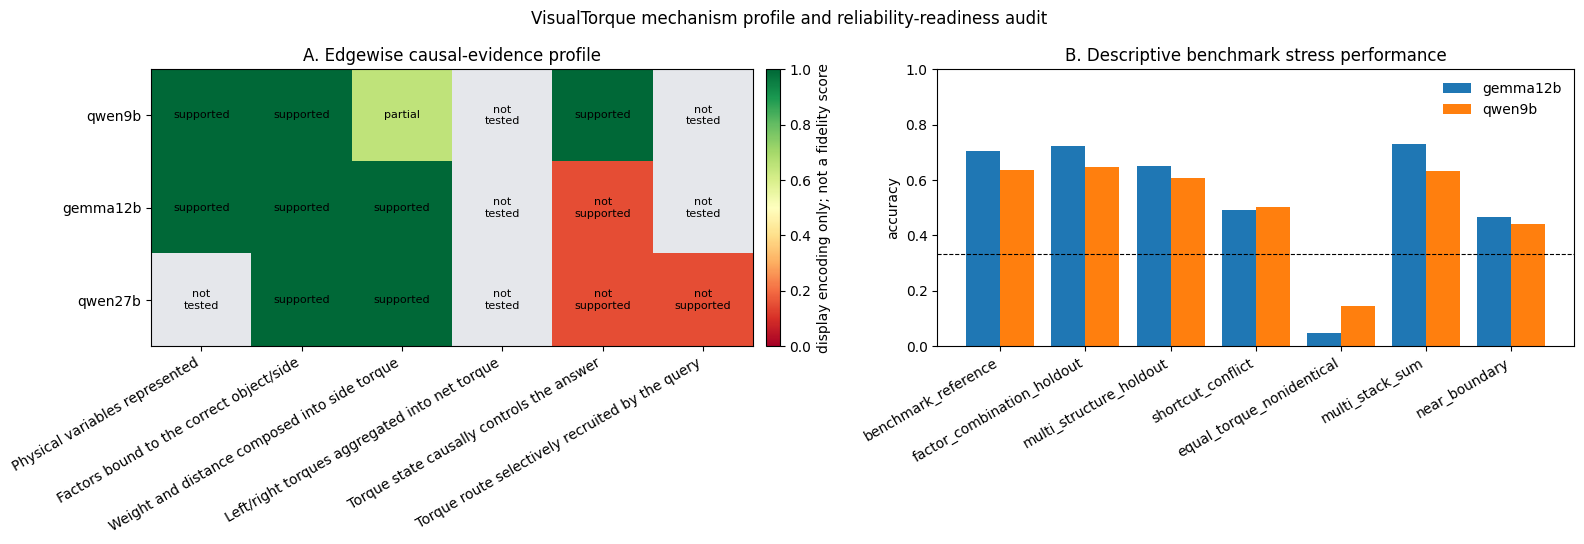

Saved: /content/drive/MyDrive/VisualTorque/results/edgewise_causal_fidelity_ood_readiness_v1/figures/edgewise_profile_and_stress_readiness.png


In [14]:
%%cell_progress 13/14 Render paper-facing mechanism and readiness figures
cell_stage('Rendering the edgewise profile and stress summary')

status_value = {
    'supported': 1.0, 'partial': 0.65, 'not_supported': 0.15,
    'inconclusive': 0.40, 'not_tested': np.nan,
}
matrix = profile_matrix.applymap(status_value.get).to_numpy(dtype=float)
masked = np.ma.masked_invalid(matrix)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ax = axes[0]
cmap = plt.cm.get_cmap('RdYlGn').copy()
cmap.set_bad('#e5e7eb')
image = ax.imshow(masked, vmin=0, vmax=1, cmap=cmap, aspect='auto')
ax.set_xticks(range(len(EDGE_ORDER)), [EDGE_LABELS[edge] for edge in EDGE_ORDER],
              rotation=30, ha='right')
ax.set_yticks(range(len(MODEL_ORDER)), MODEL_ORDER)
ax.set_title('A. Edgewise causal-evidence profile')
for row_index, model in enumerate(MODEL_ORDER):
    for column_index, edge in enumerate(EDGE_ORDER):
        status = profile_matrix.loc[model, edge]
        ax.text(column_index, row_index, status.replace('_', '\n'),
                ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=ax, fraction=.035, pad=.02,
             label='display encoding only; not a fidelity score')

ax = axes[1]
if stress_summary.empty:
    ax.text(.5, .5, 'Behavior results not found', ha='center', va='center')
    ax.set_axis_off()
else:
    plot_cohorts = ['benchmark_reference', *cohort_columns]
    plot = stress_summary[
        stress_summary['cohort'].isin(plot_cohorts)
    ].copy()
    x = np.arange(len(plot_cohorts))
    width = .8 / max(1, plot['model'].nunique())
    for index, (model, group) in enumerate(plot.groupby('model', sort=True)):
        group = group.set_index('cohort').reindex(plot_cohorts)
        values = group['accuracy'].to_numpy(dtype=float)
        ax.bar(x + (index - (plot['model'].nunique()-1)/2)*width,
               values, width=width, label=model)
    ax.axhline(1/3, color='black', linestyle='--', linewidth=.8)
    ax.set_xticks(x, plot_cohorts, rotation=30, ha='right')
    ax.set_ylim(0, 1)
    ax.set_ylabel('accuracy')
    ax.set_title('B. Descriptive benchmark stress performance')
    ax.legend(frameon=False)

fig.suptitle('VisualTorque mechanism profile and reliability-readiness audit')
fig.tight_layout()
figure_path = FIGURE_DIR / 'edgewise_profile_and_stress_readiness.png'
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', figure_path)

In [15]:
%%cell_progress 14/14 Export the paper claim ledger and next-run contract
cell_stage('Writing decision-aware reports')

claim_rows = []
for _, row in profile.iterrows():
    claim_rows.append({
        'model': str(row['model']),
        'claim': EDGE_LABELS[str(row['edge'])],
        'status': row['status'],
        'source_decision': row['source_decision'],
        'paper_interpretation': row['evidence'],
        'nonclaim': (
            'A local not-supported result is not evidence of global absence.'
            if row['status'] == 'not_supported' else ''
        ),
    })
claim_ledger = pd.DataFrame(claim_rows)
claim_ledger.to_csv(OUTPUT_DIR / 'paper_claim_ledger.csv', index=False)

current_decision = {
    'schema_version': 'visualtorque-edgewise-synthesis-decision-1.0',
    'decision': 'mechanism_profile_ready_prediction_claim_not_ready',
    'edgewise_profile_complete_for_models': list(MODEL_ORDER),
    'full_chain_supported_models': boundary_frame.loc[
        boundary_frame['full_physical_chain_supported'], 'model'
    ].tolist(),
    'qwen27b_boundary': (
        'Balanced factor-to-torque composition is supported at the relocated '
        'middle depth, while a torque-specific terminal bridge and paired '
        'query-selective route are not supported under the frozen tests.'
    ),
    'formal_prediction_ready': readiness['formal_prediction_ready'],
    'recommended_next_experiment': (
        'Collect a preregistered panel of at least eight independently measured '
        'model states across at least three families or controlled adapter arms. '
        'For every state, run the same mechanism edges, ID accuracy/confidence, '
        'probe covariate, and frozen stress panel before fitting any predictor.'
    ),
    'do_not_do_next': (
        'Do not search additional Qwen-27B heads or layers post hoc, and do not '
        'report a two- or three-model fidelity/OOD correlation.'
    ),
}
write_json_atomic(OUTPUT_DIR / 'synthesis_decision.json', current_decision)

report_lines = [
    '# VisualTorque edgewise causal-fidelity synthesis', '',
    f"- Decision: `{current_decision['decision']}`",
    f"- Formal prediction ready: {readiness['formal_prediction_ready']}",
    f"- Eligible complete model states: {readiness['eligible_model_states']}",
    '', '## Current mechanism boundary', '',
    current_decision['qwen27b_boundary'], '',
    'The current evidence supports a partial physical program: representation '
    'and binding can be present, and Qwen-27B shows depth-relocated balanced '
    'factor-to-torque composition, but the downstream side-to-net edge has not '
    'been isolated and torque-specific answer use is not established.', '',
    '## Prediction-value claim', '',
    'The current model collection is insufficient for a reviewer-defensible '
    'claim that causal fidelity predicts stress or OOD performance. The notebook '
    'therefore exports descriptive stress results and a future state registry, '
    'but intentionally does not fit a model-level correlation.', '',
    '## Next experiment', '',
    current_decision['recommended_next_experiment'], '',
    '## Analysis prohibition', '',
    current_decision['do_not_do_next'], '',
]
REPORT_PATH = OUTPUT_DIR / 'edgewise_synthesis_report.md'
REPORT_PATH.write_text('\n'.join(report_lines) + '\n', encoding='utf-8')

required_outputs = (
    'protocol_lock.json', 'source_artifacts.csv',
    'edgewise_causal_fidelity_profile.csv', 'mechanism_boundaries.csv',
    'stress_cohort_manifest.csv', 'stress_cohort_counts.csv',
    'descriptive_stress_performance.csv', 'model_state_readiness_registry.csv',
    'required_future_state_plan.csv', 'prediction_readiness.json',
    'paper_claim_ledger.csv', 'synthesis_decision.json',
    'edgewise_synthesis_report.md',
)
missing = [name for name in required_outputs if not (OUTPUT_DIR / name).is_file()]
assert not missing, missing
print(REPORT_PATH.read_text(encoding='utf-8'))
print('All outputs:', OUTPUT_DIR)

Export the paper claim ledger and next-run contract:  93%|#########2| 13/14 [00:00<?, ?cell/s]

# VisualTorque edgewise causal-fidelity synthesis

- Decision: `mechanism_profile_ready_prediction_claim_not_ready`
- Formal prediction ready: False
- Eligible complete model states: 2

## Current mechanism boundary

Balanced factor-to-torque composition is supported at the relocated middle depth, while a torque-specific terminal bridge and paired query-selective route are not supported under the frozen tests.

The current evidence supports a partial physical program: representation and binding can be present, and Qwen-27B shows depth-relocated balanced factor-to-torque composition, but the downstream side-to-net edge has not been isolated and torque-specific answer use is not established.

## Prediction-value claim

The current model collection is insufficient for a reviewer-defensible claim that causal fidelity predicts stress or OOD performance. The notebook therefore exports descriptive stress results and a future state registry, but intentionally does not fit a model-level correla